# CODE 4.2: Train the LSTM Autoencoder

> **Goal:** train the second model, an LSTM autoencoder, on the healthy February windows, and see how well it can redraw February and March windows.
>
> - **Input:** `data/processed/grid.npz` and `data/processed/windows.parquet` (3.1), `results/time_split.csv` (1.2) and `results/signals_used.json` (4.1).
> - **Output:** `models/lstm_autoencoder.pt` (the trained model) and `results/lstm_training_history.csv` (the errors after every round of training). At the end you should see **ALL CHECKS PASSED**.
>
> This notebook trains on the GPU, which takes a few minutes. Without a GPU it also works, only much slower. The test windows (April to August) are dropped right after loading; their errors are computed only in notebook 5.2, after the alarm rules are locked in notebook 5.1.

### How an LSTM Autoencoder Works

> Think of a student who has to copy a chart of one hour, but in two separate rooms:
>
> - **Room 1, the encoder.** The student reads the chart tick by tick, from the first tick to the last, and writes a short **note**: only `MEMORY_SIZE` numbers.
> - **Room 2, the decoder.** The chart stays behind. With only the note, the student redraws the whole hour: 360 ticks of every signal.
>
> The student practises on February hours only. So they learn which details matter in February: when the pump starts, how fast the pressure rises, how the oil warms up. For an hour that looks like February, the note is good enough and the redrawn hour is close to the real one. For an hour that looks different, the note misses things and the redrawing goes wrong.
>
> The **error** of a window says how far off the redrawing is: for every tick and every signal, take the distance between the real value and the redrawn value, and average. A small error means "looks like February", a large error means "unusual". Unlike the score of Isolation Forest (notebook 4.1), this error has no ceiling: the stranger the hour, the worse the redrawing can get. A section below tests this.
>
> Both rooms use an **LSTM**: it reads a sequence one step at a time and keeps a memory that it updates at every step, like reading a sentence word by word (notebook 0.1). A plain LSTM reads in one direction only, from the oldest tick to the newest, the same way time goes.

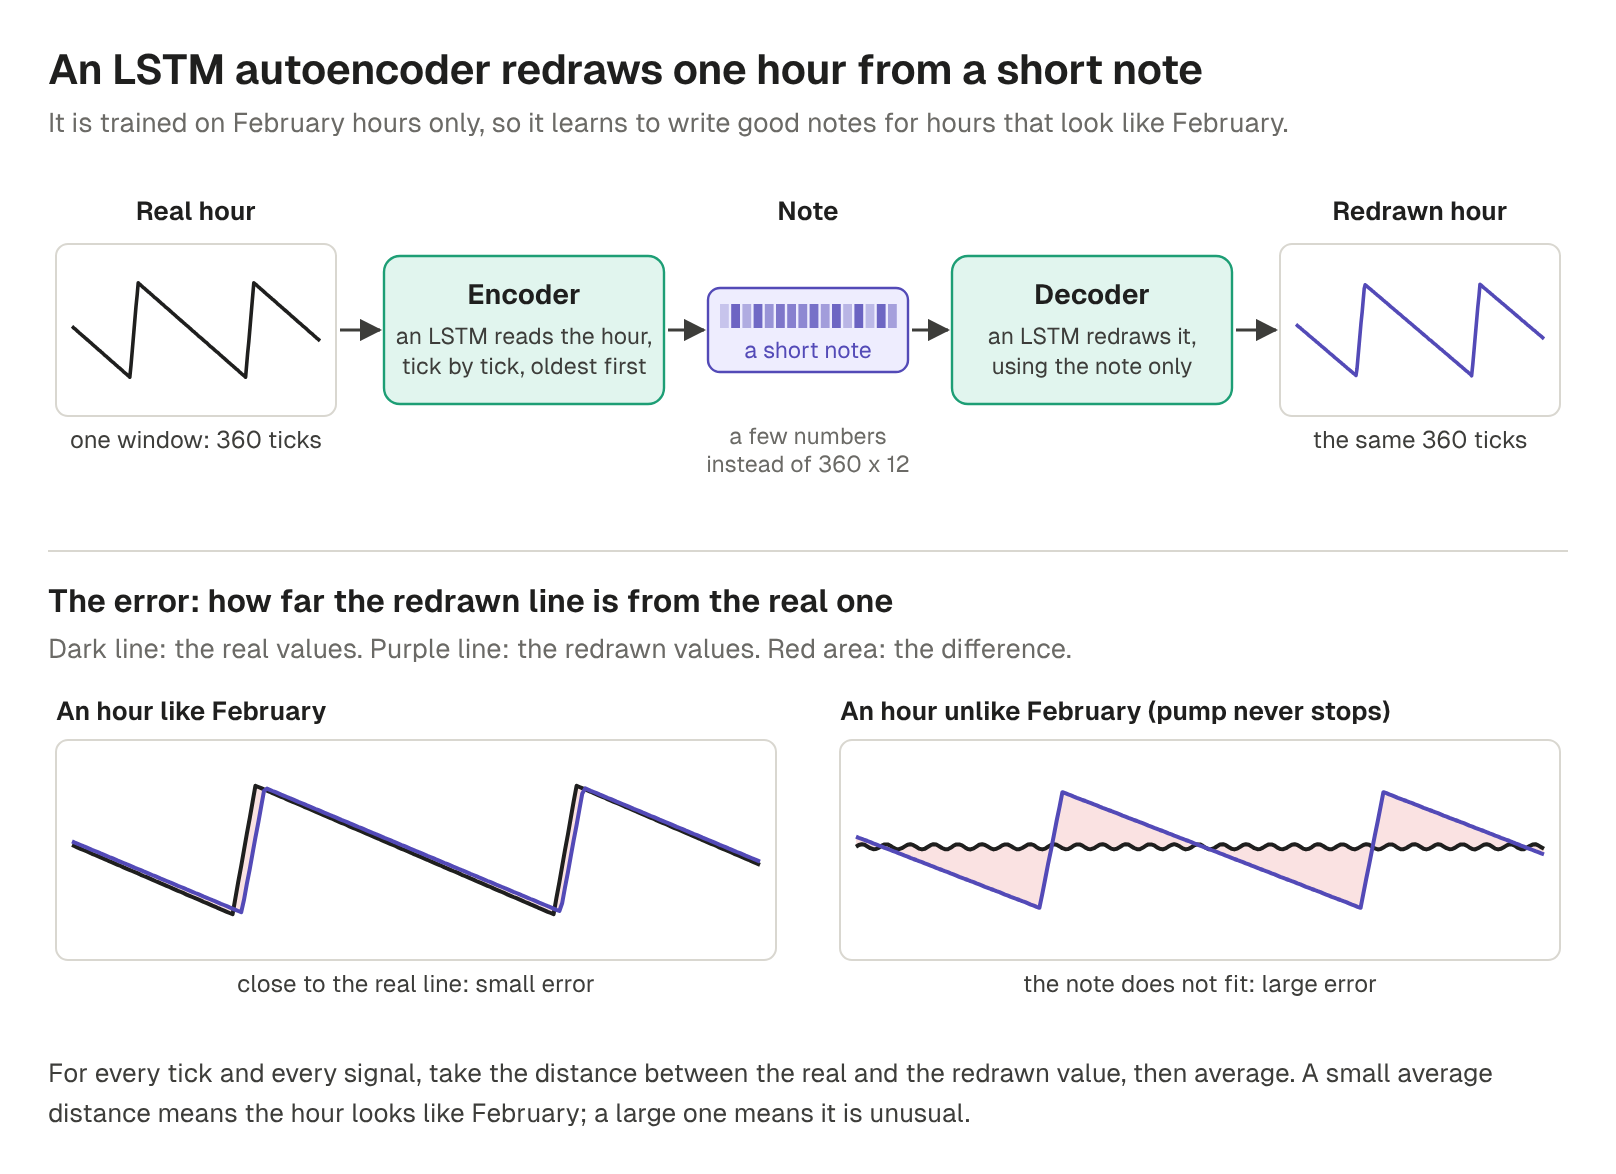

### The Input: 360 Ticks of 12 Signals

> Each window is cut out of `grid.npz`, as planned in notebook 3.1: the 360 ticks of its hour (one tick every 10 seconds), already scaled with February numbers, and the oil temperature as a change since the first tick of the window. Then we keep the 12 signals that notebook 4.1 saved in `signals_used.json`, so both models see the same signals.
>
> Cutting about 14,000 windows one by one with `lstm_window()` would be slow, so `cut_windows()` cuts them all at once with the same rule. A check compares the two for random windows.

## Import Libraries & Variables

### Import Libraries

> - `os`, `json`, `time`: folders and file paths, the signal list, and a clock for the training time.
> - `numpy`, `pandas`: numbers and tables.
> - `matplotlib`: charts.
> - `torch` (PyTorch): builds and trains the LSTM autoencoder, on the GPU.
> - `tqdm`: shows a progress bar while the model trains.

In [1]:
import os
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from tqdm import tqdm

### Variables

#### Folder Paths

> The inputs from notebooks 1.2, 3.1 and 4.1, and the two files this notebook writes.

In [2]:
ROOT_DIR = os.getcwd()
while not os.path.isfile(os.path.join(ROOT_DIR, "requirements.txt")) and ROOT_DIR != os.path.dirname(ROOT_DIR):
    ROOT_DIR = os.path.dirname(ROOT_DIR)

PROCESSED_DIR = os.path.join(ROOT_DIR, "data", "processed")
GRID_FILE = os.path.join(PROCESSED_DIR, "grid.npz")
WINDOWS_FILE = os.path.join(PROCESSED_DIR, "windows.parquet")
RESULTS_DIR = os.path.join(ROOT_DIR, "results")
SPLIT_FILE = os.path.join(RESULTS_DIR, "time_split.csv")
SIGNALS_FILE = os.path.join(RESULTS_DIR, "signals_used.json")
HISTORY_FILE = os.path.join(RESULTS_DIR, "lstm_training_history.csv")
MODELS_DIR = os.path.join(ROOT_DIR, "models")
MODEL_FILE = os.path.join(MODELS_DIR, "lstm_autoencoder.pt")
print("Project folder found:", os.path.basename(ROOT_DIR))

Project folder found: predictive-maintenance-metropt


#### Settings

> - `SIGNALS`, `OIL_COLUMN`, `WINDOW_STEPS`: the 15 signals in the order of the grid, the oil temperature column, and the 360 ticks of one window, as in notebook 3.1.
> - `MEMORY_SIZE`: how many numbers the note may have, and how big the memory of both LSTMs is.
> - `BATCH_SIZE`: how many windows the model looks at before it adjusts its weights once.
> - `LEARNING_RATE`: how big each adjustment is.
> - `MAX_GRADIENT`: the largest push allowed in one adjustment. LSTMs on long sequences sometimes want a huge push that throws everything off; it is cut back to this size.
> - `MAX_EPOCHS`, `PATIENCE`: training goes in rounds (epochs). It stops when the March error has not improved for `PATIENCE` rounds in a row, or after `MAX_EPOCHS` rounds.
> - `SEED`: fixes the random starting weights and the random order of the windows.
> - `EVAL_BATCH`: how many windows are redrawn at once when we only measure errors.
> - `CHECK_WINDOWS`: how many random windows we cut both ways to compare.
> - `SPIKE_BAR`: a `DV_pressure` reading above this many bar counts as a spike, in "Why the Distance, Not the Squared Distance".
> - `NORMAL_END`, `DEMO_MARCH_END`, `SHOW_SIGNALS`: the two windows we redraw in a chart (the same two windows as in notebook 4.1), and the three signals we show.
> - `PUSH_FACTORS`, `HALF_OF_MARCH`, `TOP_WINDOWS`: as in notebook 4.1.

In [3]:
ANALOG_COLUMNS = ["TP2", "TP3", "H1", "DV_pressure", "Reservoirs", "Oil_temperature", "Motor_current"]
DIGITAL_COLUMNS = ["COMP", "DV_eletric", "Towers", "MPG", "LPS", "Pressure_switch", "Oil_level", "Caudal_impulses"]
SIGNALS = ANALOG_COLUMNS + DIGITAL_COLUMNS
OIL_COLUMN = "Oil_temperature"
WINDOW_STEPS = 360

MEMORY_SIZE = 64
BATCH_SIZE = 64
LEARNING_RATE = 0.001
MAX_GRADIENT = 1.0
MAX_EPOCHS = 500
PATIENCE = 15
SEED = 0
EVAL_BATCH = 512
CHECK_WINDOWS = 20

SPIKE_BAR = 0.5
NORMAL_END = "2020-02-24 17:55:00"
DEMO_MARCH_END = "2020-03-29 12:00:00"
SHOW_SIGNALS = ["Reservoirs", "DV_eletric", "Oil_temperature"]
PUSH_FACTORS = [2, 5, 10]
HALF_OF_MARCH = "2020-03-16 00:00:00"
TOP_WINDOWS = 10

## Functions

### Record a Check

> `check()` prints PASS or FAIL for one check and stores the result in `results`.

In [4]:
results = {}

def check(name, ok):
    results[name] = bool(ok)
    print(("PASS  " if ok else "FAIL  ") + name)

### One Window for the LSTM, Copied from 3.1

> `lstm_window()` is copied unchanged from notebook 3.1: it cuts 360 ticks out of the scaled grid and turns the oil temperature into a change. Here it is only used to check `cut_windows()`.

In [5]:
def lstm_window(grid_scaled, end_index, window_steps, oil_index):
    window = grid_scaled[end_index - window_steps + 1:end_index + 1].copy()
    window[:, oil_index] -= window[0, oil_index]
    return window

### Cut Many Windows at Once

> `cut_windows()` does what `lstm_window()` does, for many windows at once:
>
> 1. For every window, make the list of its 360 tick numbers: from `end_index - 359` up to `end_index`.
> 2. Take all these ticks out of the grid in one go. The result has one row per window, 360 ticks and 15 signals.
> 3. From the oil temperature of every window, subtract its first tick.

In [6]:
def cut_windows(grid_values, end_indices, window_steps, oil_index):
    ticks = end_indices[:, None] - window_steps + 1 + np.arange(window_steps)[None, :]
    windows = grid_values[ticks]
    windows[:, :, oil_index] -= windows[:, :1, oil_index]
    return windows

### The Model

> `LSTMAutoencoder` is the student of the two rooms:
>
> - `encoder`: an LSTM that reads the window tick by tick. Its memory after the last tick is the **note** (`MEMORY_SIZE` numbers).
> - The note is copied 360 times, once for every tick to redraw, so the decoder gets the same note at every step.
> - `decoder`: a second LSTM that reads these copies and builds up, step by step, its own memory of what to draw.
> - `output`: turns the decoder's memory at every tick into one value per signal: the redrawn window.

In [7]:
class LSTMAutoencoder(torch.nn.Module):
    def __init__(self, n_signals, memory_size):
        super().__init__()
        self.encoder = torch.nn.LSTM(input_size=n_signals, hidden_size=memory_size, batch_first=True)
        self.decoder = torch.nn.LSTM(input_size=memory_size, hidden_size=memory_size, batch_first=True)
        self.output = torch.nn.Linear(in_features=memory_size, out_features=n_signals)

    def forward(self, windows):
        _, (memory, _) = self.encoder(windows)
        note = memory[-1].unsqueeze(1).repeat(1, windows.shape[1], 1)
        redrawn, _ = self.decoder(note)
        return self.output(redrawn)

### Train One Round

> `train_one_epoch()` shows the model every February window once, in a random order, in groups of `BATCH_SIZE`. For each group:
>
> 1. The model redraws the windows.
> 2. The error is measured: the average distance between the real and the redrawn values.
> 3. PyTorch works out how every weight should change to make the error smaller (`backward()`), the push is cut back to `MAX_GRADIENT` if it is too big, and the optimizer changes the weights a little (`step()`).
>
> It returns the average error of the round.

In [8]:
def train_one_epoch(model, windows, optimizer, batch_size, max_gradient, generator):
    model.train()
    order = torch.randperm(len(windows), generator=generator).to(windows.device)
    total = 0.0
    for start in range(0, len(windows), batch_size):
        batch = windows[order[start:start + batch_size]]
        optimizer.zero_grad()
        loss = (model(batch) - batch).abs().mean()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=max_gradient)
        optimizer.step()
        total += loss.item() * len(batch)
    return total / len(windows)

### Measure the Errors

> `window_errors()` lets the model redraw windows without learning anything (`no_grad()`), and returns two things:
>
> - the error of every window: the average distance over its 360 ticks and all signals;
> - the error of every window for every signal: the average distance over its 360 ticks, one number per signal. Notebook 5.3 uses these to explain alarms.

In [9]:
def window_errors(model, windows, batch_size):
    model.eval()
    parts = []
    with torch.no_grad():
        for start in range(0, len(windows), batch_size):
            batch = windows[start:start + batch_size]
            parts.append((model(batch) - batch).abs().mean(dim=1).cpu())
    per_signal = torch.cat(parts).numpy()
    return per_signal.mean(axis=1), per_signal

## Load the Data

### Read the Files and Drop the Test Months

> We read the grid, the list of windows and the signal list of notebook 4.1. Only the train (February) and validation (March) windows are kept.

In [10]:
with np.load(GRID_FILE) as saved:
    grid_values, grid_signals = saved["values"], saved["signals"].tolist()
    scaled_columns, scale_mean, scale_std = saved["scaled_columns"].tolist(), saved["scale_mean"], saved["scale_std"]
df_windows = pd.read_parquet(WINDOWS_FILE, columns=["end", "end_index", "split", "drop_bar_per_min"])
split_table = pd.read_csv(SPLIT_FILE).set_index("split")
validation_from = pd.Timestamp(split_table.loc["validation", "from"])
with open(SIGNALS_FILE, encoding="utf-8") as f:
    signals_used = json.load(f)["signals"]

windows_in_file = len(df_windows)
df_windows = df_windows[df_windows["split"].isin(["train", "validation"])].reset_index(drop=True)
is_train, is_march = (df_windows["split"] == "train").to_numpy(), (df_windows["split"] == "validation").to_numpy()
signal_columns = [grid_signals.index(signal) for signal in signals_used]

print(f"Windows in the file: {windows_in_file:,} | kept: {len(df_windows):,} (February {is_train.sum():,}, March {is_march.sum():,})")
print(f"Signals for the LSTM: {len(signals_used)} of {len(grid_signals)} ->", signals_used)
check("only February and March windows are kept", set(df_windows["split"].unique()) <= {"train", "validation"})
check(f"the {len(signals_used)} signals of notebook 4.1 are in the grid, in the order of the grid", grid_signals == SIGNALS and signal_columns == sorted(signal_columns))

Windows in the file: 47,491 | kept: 13,984 (February 6,790, March 7,194)
Signals for the LSTM: 12 of 15 -> ['TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs', 'Oil_temperature', 'Motor_current', 'COMP', 'DV_eletric', 'Towers', 'MPG', 'Pressure_switch']
PASS  only February and March windows are kept
PASS  the 12 signals of notebook 4.1 are in the grid, in the order of the grid


### Cut the Windows

> All February and March windows are cut at once, checked against `lstm_window()`, and then reduced to the 12 signals. The full grid of 15 signals is not needed after that.

In [11]:
oil_index = grid_signals.index(OIL_COLUMN)
all_windows = cut_windows(grid_values=grid_values, end_indices=df_windows["end_index"].to_numpy(), window_steps=WINDOW_STEPS, oil_index=oil_index)
sample = np.random.default_rng(SEED).choice(len(df_windows), size=CHECK_WINDOWS, replace=False)
same = [np.array_equal(all_windows[i], lstm_window(grid_scaled=grid_values, end_index=int(df_windows.loc[i, "end_index"]), window_steps=WINDOW_STEPS, oil_index=oil_index))
        for i in sample]
inputs = np.ascontiguousarray(all_windows[:, :, signal_columns])
del all_windows

print(f"Inputs: {inputs.shape[0]:,} windows x {inputs.shape[1]} ticks x {inputs.shape[2]} signals ({inputs.nbytes / 1e6:,.0f} MB)")
check(f"cutting all windows at once gives the same {CHECK_WINDOWS} random windows as lstm_window()", all(same))
check("no window has a missing value", not np.isnan(inputs).any())

Inputs: 13,984 windows x 360 ticks x 12 signals (242 MB)
PASS  cutting all windows at once gives the same 20 random windows as lstm_window()
PASS  no window has a missing value


### Why the Distance, Not the Squared Distance

> Many autoencoders measure their error with **squared** distances. We use the plain distance (the mean absolute error). The reason is one signal: `DV_pressure` stays almost exactly at the same value all February, with now and then a short spike. Notebook 3.1 scaled every signal by its February spread, and that spread is tiny here, so one spike is a huge number after scaling. This cell measures it on February only.

In [12]:
dv_position = signals_used.index("DV_pressure")
dv_scaled = scaled_columns.index("DV_pressure")
february_dv = inputs[is_train][:, :, dv_position]
spike_level = (SPIKE_BAR - scale_mean[dv_scaled]) / scale_std[dv_scaled]
highest = float(february_dv.max())

print(f"February windows with a DV_pressure reading above {SPIKE_BAR} bar: {(february_dv > spike_level).any(axis=1).mean():.0%}")
print(f"Highest DV_pressure reading in February: {highest * scale_std[dv_scaled] + scale_mean[dv_scaled]:.1f} bar, "
      f"which is {highest:.0f} February spreads above the February average")
print(f"In the error of a window, that one reading counts like {highest:.0f} readings that are one spread off with the distance, "
      f"and like {highest ** 2:,.0f} of them with the squared distance")

February windows with a DV_pressure reading above 0.5 bar: 27%
Highest DV_pressure reading in February: 6.5 bar, which is 62 February spreads above the February average
In the error of a window, that one reading counts like 62 readings that are one spread off with the distance, and like 3,870 of them with the squared distance


> **What we see:** short `DV_pressure` spikes are normal in February: a good share of the February windows has one. With squared distances, a single spike would count as much as a whole window of other mistakes, so the error would mostly say "was there a spike or not". With the plain distance, a spike still counts, but it cannot drown out everything else. A change that lasts, like the long stretches in March, still adds up to a large error.

## Train the Model

### Choose the Device

> Training runs on the GPU if PyTorch finds one (notebook 0.1 checked this).

In [13]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training on:", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU (no GPU found: this works, but slowly)")

Training on: NVIDIA GeForce RTX 5070 Laptop GPU


### Build the Model

> We fix the random starting point, build the model, and move the February and March windows to the device. The **weights** are the numbers the training adjusts: all the knobs inside both LSTMs and the output layer. **Adam** is the optimizer that decides how much to turn each knob after every group of windows.
>
> On a GPU, two runs can still differ in the last digits, even with the same seed, because the GPU adds numbers up in a slightly different order. So your errors may differ a little from someone else's run; the checks allow for that.

In [14]:
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
model = LSTMAutoencoder(n_signals=len(signals_used), memory_size=MEMORY_SIZE).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
february_tensor = torch.from_numpy(inputs[is_train]).to(device)
march_tensor = torch.from_numpy(inputs[is_march]).to(device)

print(f"Weights to learn: {sum(weight.numel() for weight in model.parameters()):,}")
print(f"February windows: {tuple(february_tensor.shape)} | March windows: {tuple(march_tensor.shape)} | device: {device.type}")

Weights to learn: 54,028
February windows: (6790, 360, 12) | March windows: (7194, 360, 12) | device: cuda


### Training with Early Stopping

> Training goes in rounds. In every round the model sees all February windows once (`train_one_epoch()`). After every round we measure the **middle error (median) of the March windows**, and we keep a copy of the weights from the best round so far.
>
> - **Why March?** Think of studying for an exam with practice questions from another month. You stop when you no longer get better at the practice questions; after that you would only be memorising February. This is called **early stopping**.
> - **Why the middle error?** March has a few very strange hours (notebook 3.2). With the average, these few hours could decide when training stops. The middle error looks at the typical March window.
>
> At the end, the weights of the best round are put back into the model.

In [15]:
generator = torch.Generator().manual_seed(SEED)
history = []
best_error, best_epoch, best_state, rounds_without_better = np.inf, 0, None, 0
started = time.time()
progress = tqdm(range(1, MAX_EPOCHS + 1), desc="Training rounds")
for epoch in progress:
    train_error = train_one_epoch(model=model, windows=february_tensor, optimizer=optimizer, batch_size=BATCH_SIZE,
                                  max_gradient=MAX_GRADIENT, generator=generator)
    march_middle = float(np.median(window_errors(model=model, windows=march_tensor, batch_size=EVAL_BATCH)[0]))
    history.append({"epoch": epoch, "february_train_error": train_error, "march_middle_error": march_middle, "seconds": time.time() - started})
    if march_middle < best_error:
        best_error, best_epoch, rounds_without_better = march_middle, epoch, 0
        best_state = {name: value.detach().clone() for name, value in model.state_dict().items()}
    else:
        rounds_without_better += 1
    progress.set_postfix(february=f"{train_error:.4f}", march=f"{march_middle:.4f}", best_round=best_epoch)
    if rounds_without_better >= PATIENCE:
        break
progress.close()
model.load_state_dict(best_state)
df_history = pd.DataFrame(history)

print(f"Rounds trained: {len(df_history)} of at most {MAX_EPOCHS} | stopped early: {'yes' if rounds_without_better >= PATIENCE else 'no'} | time: {df_history['seconds'].iloc[-1] / 60:.1f} minutes")
print(f"Best round: {best_epoch} | March middle error there: {best_error:.4f}")
check("the model learned from February windows only", len(february_tensor) == is_train.sum() and (df_windows.loc[is_train, "end"] < validation_from).all())
check("the training error went down", df_history["february_train_error"].iloc[-1] < df_history["february_train_error"].iloc[0])

Training rounds:   0%|          | 0/500 [00:00<?, ?it/s]

Training rounds:  33%|███▎      | 163/500 [01:38<03:22,  1.66it/s, best_round=149, february=0.1068, march=0.2655]

Rounds trained: 164 of at most 500 | stopped early: yes | time: 1.6 minutes
Best round: 149 | March middle error there: 0.2500
PASS  the model learned from February windows only
PASS  the training error went down


### The Learning Curve

> The error after every round: the February training error (the windows the model learns from) and the middle March error (the windows used for early stopping). The dashed line marks the best round, whose weights we keep.

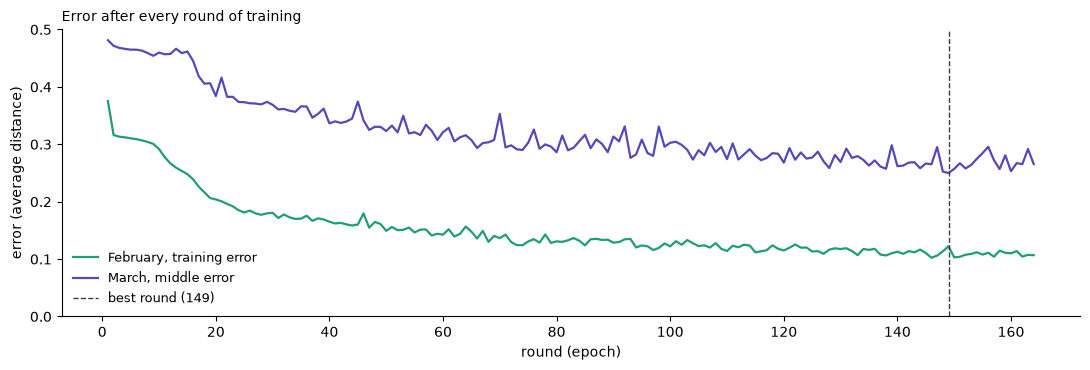

In [16]:
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(df_history["epoch"], df_history["february_train_error"], color="#1D9E75", linewidth=1.6, label="February, training error")
ax.plot(df_history["epoch"], df_history["march_middle_error"], color="#534AB7", linewidth=1.6, label="March, middle error")
ax.axvline(best_epoch, color="#3D3D3A", linestyle="--", linewidth=1, label=f"best round ({best_epoch})")
ax.set_xlabel("round (epoch)")
ax.set_ylabel("error (average distance)")
ax.set_ylim(bottom=0)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, fontsize=9)
ax.set_title("Error after every round of training", fontsize=10, loc="left")
plt.tight_layout()
plt.show()

> **What we see:** both errors go down while the model learns: the February training error fast at first, then slowly. The March middle error stays above the February error the whole time, because March differs from February (notebook 3.2), and it moves up and down a little from round to round. The dashed line marks the round with the lowest March middle error, whose weights we keep. Training stopped either because `PATIENCE` rounds in a row did not beat that round, or after `MAX_EPOCHS` rounds (see the lines printed above the chart).

## Look at the Errors

### Errors of February and March

> With the weights of the best round, every February and March window is redrawn once more, and its error is stored. The table and the chart compare the two months, as in notebook 4.1.

,count,min,50%,90%,99%,max
split,,,,,,
February,6790.0,0.024,0.074,0.197,0.276,0.458
March,7194.0,0.061,0.250,0.622,2.002,2.738


February windows below the March middle error: 98%
March windows above the highest February error: 1,316 of 7,194


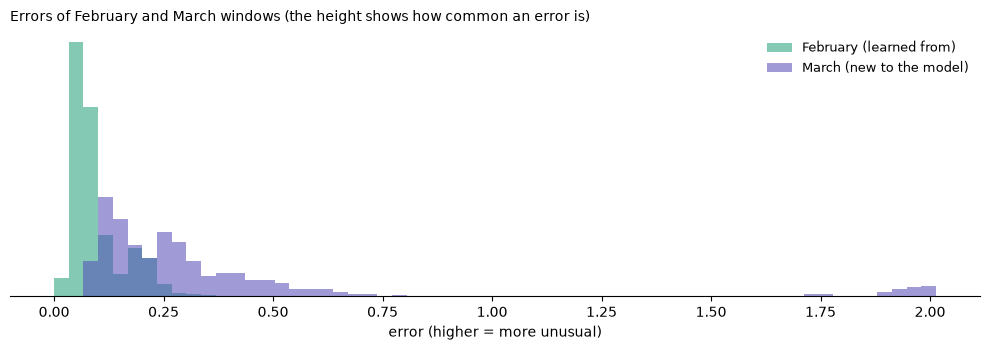

PASS  every February and March window has a finite error


In [17]:
february_errors, february_signal_errors = window_errors(model=model, windows=february_tensor, batch_size=EVAL_BATCH)
march_errors, march_signal_errors = window_errors(model=model, windows=march_tensor, batch_size=EVAL_BATCH)
df_windows["error"] = np.nan
df_windows.loc[is_train, "error"] = february_errors
df_windows.loc[is_march, "error"] = march_errors
df_signal_errors = pd.DataFrame(np.vstack([february_signal_errors, march_signal_errors]), columns=signals_used,
                                index=np.concatenate([np.flatnonzero(is_train), np.flatnonzero(is_march)])).sort_index()

summary = df_windows.groupby("split")["error"].describe(percentiles=[0.5, 0.9, 0.99])[["count", "min", "50%", "90%", "99%", "max"]]
display(summary.rename(index={"train": "February", "validation": "March"}).round(3))
print(f"February windows below the March middle error: {(february_errors < np.median(march_errors)).mean():.0%}")
print(f"March windows above the highest February error: {(march_errors > february_errors.max()).sum():,} of {len(march_errors):,}")

fig, ax = plt.subplots(figsize=(10, 3.6))
bins = np.linspace(0, np.percentile(march_errors, 99.5), 61)
ax.hist(february_errors, bins=bins, density=True, alpha=0.55, color="#1D9E75", label="February (learned from)")
ax.hist(march_errors, bins=bins, density=True, alpha=0.55, color="#534AB7", label="March (new to the model)")
ax.set_xlabel("error (higher = more unusual)")
ax.set_yticks([])
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, fontsize=9)
ax.set_title("Errors of February and March windows (the height shows how common an error is)", fontsize=10, loc="left")
plt.tight_layout()
plt.show()

check("every February and March window has a finite error", np.isfinite(df_windows["error"]).all())

> **What we see:** most February windows have small errors: the model learned to redraw them. March is shifted to the right: the middle March error is higher than most February errors (see the share printed above). So, to a model that learned February, much of March looks somewhat unusual, just as for Isolation Forest.
>
> The difference is on the far right: a separate group of March windows has errors several times larger than any February window, and many more March windows than in notebook 4.1 lie above the highest February value. The LSTM does not squeeze the strangest hours together under a ceiling.

### February and March, Day by Day

> Each dot is one window at its end time, as in notebook 4.1. The grey bands are the stretches of pumping without a break (notebook 3.2), and the dashed line is the highest error of any February window. The error axis is logarithmic: every step up means ten times larger, so the small February errors and the very large March errors fit in one chart.

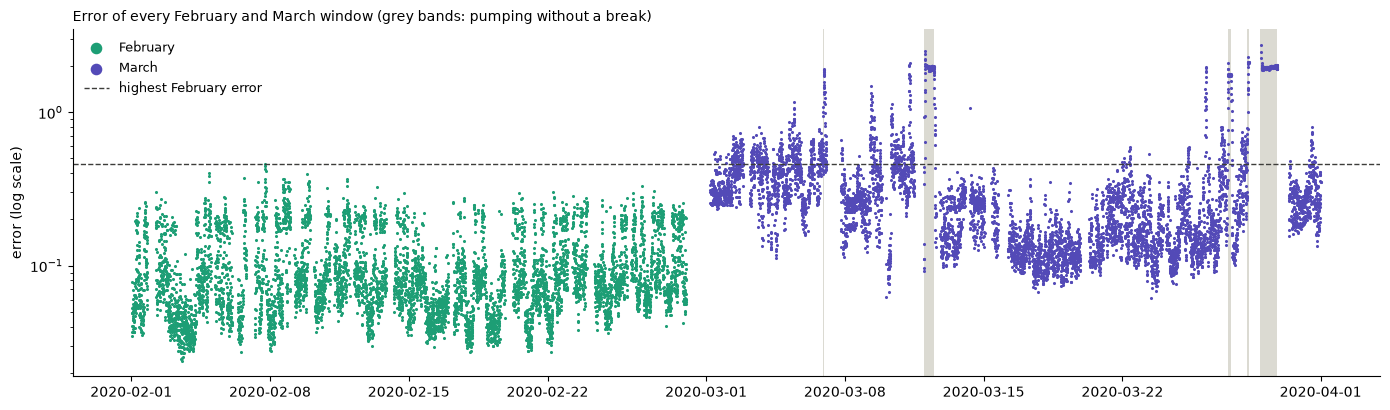

Middle error (median): {'February': 0.074, 'March 1-15': 0.317, 'March 16-31': 0.167, 'March, pumping without a break': 1.959}
Windows without a pump break above the highest February error: 414 of 414


In [18]:
whole_hour = df_windows.loc[is_march & (df_windows["drop_bar_per_min"] == 0)]
new_stretch = whole_hour["end"].diff() != pd.Timedelta(minutes=5)
stretches = whole_hour.groupby(new_stretch.cumsum()).agg(first_end=("end", "min"), until=("end", "max"))
stretches["pumping_from"] = stretches["first_end"] - pd.Timedelta(minutes=60)
first_half = is_march & (df_windows["end"] < pd.Timestamp(HALF_OF_MARCH)).to_numpy()
second_half = is_march & (df_windows["end"] >= pd.Timestamp(HALF_OF_MARCH)).to_numpy()

fig, ax = plt.subplots(figsize=(14, 4.2))
for row in stretches.itertuples():
    ax.axvspan(row.pumping_from, row.until, color="#D3D1C7", alpha=0.8, linewidth=0)
ax.scatter(df_windows.loc[is_train, "end"], february_errors, s=1.5, color="#1D9E75", label="February")
ax.scatter(df_windows.loc[is_march, "end"], march_errors, s=1.5, color="#534AB7", label="March")
ax.axhline(february_errors.max(), color="#3D3D3A", linestyle="--", linewidth=1, label="highest February error")
ax.set_yscale("log")
ax.set_ylabel("error (log scale)")
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, fontsize=9, loc="upper left", markerscale=6)
ax.set_title("Error of every February and March window (grey bands: pumping without a break)", fontsize=10, loc="left")
plt.tight_layout()
plt.show()

middles = pd.Series({"February": np.median(february_errors), "March 1-15": df_windows.loc[first_half, "error"].median(),
                     "March 16-31": df_windows.loc[second_half, "error"].median(),
                     "March, pumping without a break": df_windows.loc[whole_hour.index, "error"].median()})
print("Middle error (median):", middles.round(3).to_dict())
print(f"Windows without a pump break above the highest February error: {(df_windows.loc[whole_hour.index, 'error'] > february_errors.max()).sum()} of {len(whole_hour)}")

> **What we see:** February stays low. In March, the error is highest in the first half and during the stretches without a pump break, which lie far above the dashed line (the last printed line counts how many of their windows do). The second half of March comes down, closer to February. Unlike Isolation Forest, the LSTM lets the stretches without a pump break stand out clearly from the rest of March.

### The Most Unusual March Windows

> The March windows with the largest errors. For each one we also show which signal was redrawn worst, and how much of the window's error comes from that signal.

In [19]:
top = df_windows.loc[is_march].nlargest(TOP_WINDOWS, "error")
top_signals = df_signal_errors.loc[top.index]
top_table = pd.DataFrame({"error": top["error"].to_numpy(), "worst signal": top_signals.idxmax(axis=1).to_numpy(),
                          "share of the error": (top_signals.max(axis=1) / top_signals.sum(axis=1)).map("{:.0%}".format).to_numpy(),
                          "pump never rested": (top["drop_bar_per_min"] == 0).to_numpy()},
                         index=top["end"].dt.strftime("%d %b %H:%M"))
display(top_table.round(3))
print("Days of March in this list:", sorted(top["end"].dt.day.unique().tolist()))

,error,worst signal,share of the error,pump never rested
end,,,,
29 Mar 00:10,2.738,Oil_temperature,25%,True
12 Mar 01:15,2.518,DV_pressure,22%,False
29 Mar 00:15,2.457,DV_pressure,20%,True
12 Mar 01:10,2.388,DV_pressure,22%,False
28 Mar 08:20,2.301,DV_pressure,24%,False
29 Mar 00:20,2.255,DV_pressure,23%,True
12 Mar 01:20,2.230,DV_pressure,26%,True
12 Mar 01:25,2.174,DV_pressure,26%,True
28 Mar 08:15,2.140,DV_pressure,24%,False


Days of March in this list: [12, 28, 29]


> **What we see:** this list is different from the one of Isolation Forest in notebook 4.1, which held only windows from 9 to 11 March. Here it holds windows from the stretches without a pump break and from other unusual hours of March (see the days printed above). The worst signal holds only part of each window's error (see the share column): these windows are off in several signals at once. `DV_pressure` is often the worst one; the next table shows how much harder it is to redraw in March.

### Which Signals Are Hardest to Redraw?

> For every signal, the middle error over all February windows and over all March windows. The last column shows how many times larger the March error is.

In [20]:
signal_table = pd.DataFrame({"February": df_signal_errors.loc[np.flatnonzero(is_train)].median(),
                             "March": df_signal_errors.loc[np.flatnonzero(is_march)].median()})
signal_table["March / February"] = signal_table["March"] / signal_table["February"]
display(signal_table.sort_values("March / February", ascending=False).round(3))

,February,March,March / February
Oil_temperature,0.154,0.878,5.700
Motor_current,0.072,0.380,5.250
DV_pressure,0.023,0.117,5.130
DV_eletric,0.016,0.057,3.641
COMP,0.016,0.058,3.521
MPG,0.016,0.058,3.511
TP2,0.068,0.229,3.365
H1,0.097,0.308,3.193
TP3,0.176,0.359,2.040
Reservoirs,0.177,0.359,2.035


> **What we see:** every signal is harder to redraw in March than in February. The table is sorted by how much: at the top are the signals that March changes most, such as the oil temperature, `DV_pressure` and the motor current, followed by the pump signals (`DV_eletric`, `COMP`, `MPG`). That fits notebook 3.2: March changes how the compressor runs and how the oil warms up. The tank pressures (`TP3`, `Reservoirs`) change less. Notebook 5.3 will use these errors per signal to explain each alarm.

### Two Windows, Redrawn

> The two windows of notebook 4.1, redrawn by the model: a normal February window and a March window without a pump break. Each panel shows one signal in its scaled units: the real values (dark) and the redrawn values (purple).

A normal February window (24 Feb 17:55): error 0.163
A March window without a pump break (29 Mar 12:00): error 1.992


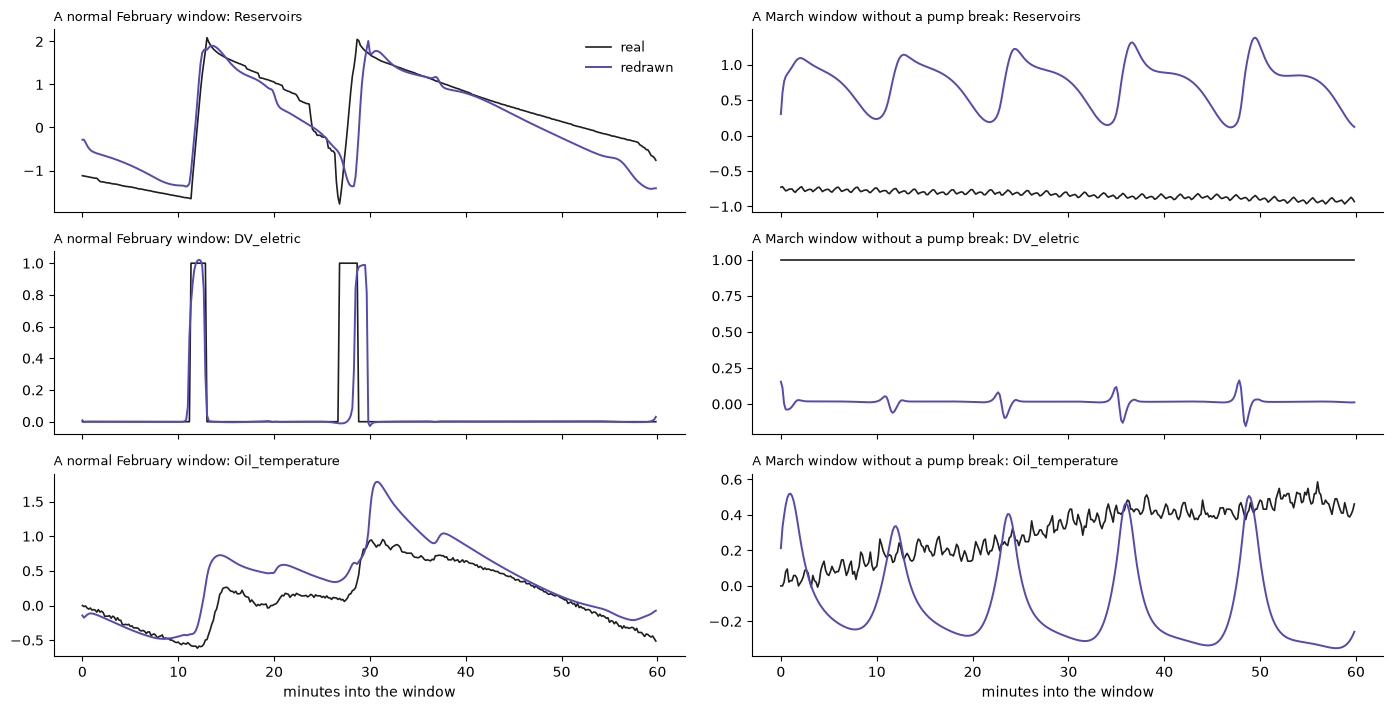

In [21]:
examples = [("A normal February window", NORMAL_END), ("A March window without a pump break", DEMO_MARCH_END)]
fig, axes = plt.subplots(len(SHOW_SIGNALS), len(examples), figsize=(14, 7.2), sharex=True)
minutes = np.arange(WINDOW_STEPS) * 10 / 60
for col, (title, end) in enumerate(examples):
    position = int(np.flatnonzero((df_windows["end"] == pd.Timestamp(end)).to_numpy())[0])
    real = torch.from_numpy(inputs[[position]]).to(device)
    model.eval()
    with torch.no_grad():
        redrawn = model(real)[0].cpu().numpy()
    print(f"{title} ({pd.Timestamp(end):%d %b %H:%M}): error {df_windows.loc[position, 'error']:.3f}")
    for row, signal in enumerate(SHOW_SIGNALS):
        ax = axes[row, col]
        ax.plot(minutes, inputs[position, :, signals_used.index(signal)], color="#1F1F1E", linewidth=1.2, label="real")
        ax.plot(minutes, redrawn[:, signals_used.index(signal)], color="#534AB7", linewidth=1.4, label="redrawn")
        ax.set_title(f"{title}: {signal}", fontsize=9.5, loc="left")
        for side in ["top", "right"]:
            ax.spines[side].set_visible(False)
    axes[-1, col].set_xlabel("minutes into the window")
axes[0, 0].legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

> **What we see:** the normal February window is redrawn closely: the two pump runs come at the right minutes, and the tank pressure and the oil temperature follow the real lines. The March window is redrawn as if it were a February hour: the redrawn lines look like a normal pump cycle, while in reality the pump never stopped and the pressure stayed flat. The gap between the dark and the purple lines is the error.

### No Ceiling

> In notebook 4.1, the score of Isolation Forest barely moved when we pushed the March window ending at `DEMO_MARCH_END` further and further away from February. Here we do the same with the LSTM: for every signal we take its February middle value, and push every value of the window 2, 5 and 10 times as far away from it. Then the model redraws the pushed windows.

In [22]:
middle = np.median(inputs[is_train].reshape(-1, len(signals_used)), axis=0)
position = int(np.flatnonzero((df_windows["end"] == pd.Timestamp(DEMO_MARCH_END)).to_numpy())[0])
pushed = np.stack([middle + factor * (inputs[position] - middle) for factor in [1] + PUSH_FACTORS]).astype("float32")
pushed_errors = window_errors(model=model, windows=torch.from_numpy(pushed).to(device), batch_size=EVAL_BATCH)[0]

print(f"Window ending {DEMO_MARCH_END}: error as it is {pushed_errors[0]:.3f}")
for factor, error in zip(PUSH_FACTORS, pushed_errors[1:]):
    print(f"Every value pushed {factor} times as far from February: {error:.3f}")
check("the further the window is pushed, the larger its error", bool(np.all(np.diff(pushed_errors) > 0)))

Window ending 2020-03-29 12:00:00: error as it is 1.992
Every value pushed 2 times as far from February: 3.809
Every value pushed 5 times as far from February: 9.217
Every value pushed 10 times as far from February: 18.530
PASS  the further the window is pushed, the larger its error


> **What we see:** the error keeps growing as the window is pushed further, roughly in step with the push: twice as far gives about twice the error (compare the numbers printed above). There is no ceiling: the stranger the window, the worse the model redraws it. This is the opposite of Isolation Forest in notebook 4.1, whose score barely moved.

## Save

### What Will Be Written

> A preview of the two files this notebook writes, and whether they exist already.

In [23]:
for path in [MODEL_FILE, HISTORY_FILE]:
    print(f"{os.path.relpath(path, ROOT_DIR)}: {'exists, will be replaced' if os.path.exists(path) else 'new file'}")

models\lstm_autoencoder.pt: new file
results\lstm_training_history.csv: new file


### Save the Model and the Training History

> - `models/lstm_autoencoder.pt`: the weights of the best round, together with the settings needed to rebuild the model (the signals, `MEMORY_SIZE`, `WINDOW_STEPS`) and the best round. The file holds only numbers, text and lists, so it can be loaded safely with `weights_only=True`: loading it cannot run any code.
> - `results/lstm_training_history.csv`: the two errors after every round, and the time.

In [24]:
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
torch.save({"state_dict": {name: value.cpu() for name, value in model.state_dict().items()}, "signals": signals_used,
            "memory_size": MEMORY_SIZE, "window_steps": WINDOW_STEPS, "best_epoch": best_epoch}, MODEL_FILE)
df_history.to_csv(HISTORY_FILE, index=False)

for path in [MODEL_FILE, HISTORY_FILE]:
    print(f"Saved {os.path.relpath(path, ROOT_DIR)} ({os.path.getsize(path) / 1024:,.0f} KB)")

Saved models\lstm_autoencoder.pt (215 KB)
Saved results\lstm_training_history.csv (10 KB)


### Read the Files Back

> We load the model file again, as notebooks 5.1 to 5.3 will: build a new, empty model with the saved settings, put the saved weights into it, and let it redraw the March windows. Its errors must match the errors above (up to the last digits).

In [25]:
saved = torch.load(MODEL_FILE, map_location=device, weights_only=True)
loaded_model = LSTMAutoencoder(n_signals=len(saved["signals"]), memory_size=saved["memory_size"]).to(device)
loaded_model.load_state_dict(saved["state_dict"])
loaded_errors = window_errors(model=loaded_model, windows=march_tensor, batch_size=EVAL_BATCH)[0]

print(f"Largest difference in the March errors: {np.abs(loaded_errors - march_errors).max():.2e}")
check("the saved model gives the same March errors", np.allclose(loaded_errors, march_errors, rtol=1e-5, atol=1e-6))
check("the saved file holds the signals, the note size and the best round",
      saved["signals"] == signals_used and saved["memory_size"] == MEMORY_SIZE and saved["best_epoch"] == best_epoch)

Largest difference in the March errors: 0.00e+00
PASS  the saved model gives the same March errors
PASS  the saved file holds the signals, the note size and the best round


## Result

### Final Result

> If every check passed, the LSTM autoencoder is trained on February only, early-stopped on March, and saved. If a check failed, its name is printed.

In [26]:
failed = [name for name, ok in results.items() if not ok]
if results and not failed:
    print(f"ALL CHECKS PASSED ({len(results)} checks)")
else:
    print(f"{len(failed)} of {len(results)} checks FAILED:")
    for name in failed:
        print("  -", name)

ALL CHECKS PASSED (10 checks)


## Summary

> - The LSTM autoencoder reads a window of 360 ticks and 12 signals, writes a note of `MEMORY_SIZE` numbers, and redraws the window from that note. Its error, the average distance between the real and the redrawn values, says how unusual a window is.
> - It uses the plain distance instead of the squared one, so that short, normal `DV_pressure` spikes do not decide the error.
> - It learned from February only and stopped early on the middle March error. The weights of the best round are saved in `models/lstm_autoencoder.pt`.
> - Like Isolation Forest, it finds much of March somewhat unusual. Unlike Isolation Forest, its error has no ceiling: the hours without a pump break stand far above every February window.
> - Notebook 5.1 sets the alarm limits of both models on March, leaving out the unusual March hours, as decided after notebook 3.2.
>
> **Next:** `notebooks/5_evaluation/5.1_set_alarm_rules.ipynb`